# Experiment 1 — Early-life timelines of reference accounts

**Question:** do the watchlist (reference) accounts share a *staging phase* early in life —
seed deposit → quiet period with charges eating the balance → sudden "awakening" — and is that
phase rarer among ordinary accounts? Or is FRONTIER a one-off?

**Scope and safety**
- Read-only. Separate from `aml_screening.py`; writes nothing to the reporting DB. Outputs go to `outputs/early_signals/`.
- Same source as production (`HIST_TRAN_DTL_TABLE` × `GENERAL_ACCT_MAST_TABLE`, USD, opened ≥ 2024-01-01, closed included).
- **Difference from production:** charges (`RPT_CODE` CHG/INT) and GL legs are *kept as separate streams* instead of dropped,
  because the staging signal is made of exactly those transactions.
- Time axis is **days since `ACCT_OPN_DATE`** (not calendar time, and not the pipeline's `account_age_days`).

**How to run:** leave `SYNTHETIC = True` to dry-run end to end on generated data. Set it to `False` to run on real data;
connections use the production `.env` (`AML_READ_*` for Finacle, `AML_WRITE_*` for the reporting DB) — set `ENV_FILE` if
the notebook isn't in the same folder as `.env`.

**Gate at the end:** decide whether the dormancy → burst pattern is worth a lead-time test.

In [1]:
import re
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SYNTHETIC = False          # False = real data via get_engines()

WINDOW_DAYS     = 180     # early-life window, in days since opening
EARLY_DAYS      = 90      # sub-window for the charge-share metric
ACTIVE_MIN_USD  = 100     # a day counts as 'active' only if customer turnover >= this (tiny entries don't break dormancy)
DORMANT_MIN_DAYS = 30     # dormant start = awakening on/after this day...
PRE_WAKE_MAX_SHARE = 0.05 # ...with at most this share of window turnover before it
RUN_GAP_DAYS    = 14      # customer activity separated by >= this many silent days starts a new "run"
RUN_SHARE       = 0.30    # awakening = start of the first run carrying >= 30% of window turnover
WAKE_DAYS       = 14      # look-ahead after awakening for the intensity metrics
# Candidate "dormant then burst" rule — starting values to inspect, not tuned thresholds
WAKE_MIN_USD    = 50_000  # turnover in the first WAKE_DAYS after awakening
WAKE_MIN_MATCH  = 0.5     # pass-through: min(credits, debits) / max(credits, debits) in that period
WAKE_MIN_ACTIVE_DAYS = 3  # spread: active days in that period (rules out a single in/out pair)
BASELINE_N      = 200     # random unflagged comparison accounts
RANDOM_SEED     = 42
FOCUS_NAME      = "FRONTIER"   # account name substring to inspect in detail

AS_OF = pd.Timestamp.today().normalize()
OUT = Path("outputs/early_signals"); OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Connections and queries

In [2]:
import os

# Same .env as production. Point ENV_FILE at it if the notebook runs from another folder.
ENV_FILE = ".env"
try:
    from dotenv import load_dotenv
    load_dotenv(ENV_FILE, override=False)
except ImportError:
    print("python-dotenv not installed; relying on variables already in the environment")

def _engine(prefix):
    '''Copied from aml_screening.py so the experiment doesn't import (or depend on) the production script.
    READ = Finacle, WRITE = reporting DB (used here for SELECTs only; the notebook writes nothing).'''
    from sqlalchemy import create_engine, URL

    full_url = os.environ.get(f"AML_{prefix}_URL")
    if full_url:
        return create_engine(full_url, fast_executemany=True)

    def req(name):
        val = os.environ.get(f"AML_{prefix}_{name}")
        if not val:
            raise RuntimeError(f"Set AML_{prefix}_{name} (or provide a full AML_{prefix}_URL)")
        return val

    url = URL.create(
        "mssql+pyodbc",
        username=req("USER"),
        password=req("PWD"),
        host=req("HOST"),
        port=int(os.environ.get(f"AML_{prefix}_PORT", "1433")),
        database=req("DB"),
        query={"driver": os.environ.get("AML_ODBC_DRIVER", "ODBC Driver 17 for SQL Server")},
    )
    return create_engine(url, fast_executemany=True)

def get_engines():
    '''Return (finacle_engine, reporting_engine).'''
    return _engine("READ"), _engine("WRITE")

FIN = "RSVRRealtimeFinacleUGPRD.TBAADM"

# Population for the baseline: same filters as production, accounts with at least one transaction.
# Only accounts old enough to show the whole window can be baseline, so younger ones are excluded in SQL
# (smaller scan). This is the slow query — it is cached and only re-run when the cache is stale.
POPULATION_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE gm
WHERE gm.ACCT_CRNCY_CODE = 'USD'
  AND gm.ACCT_OPN_DATE >= '2024-01-01'
  AND gm.ACCT_OPN_DATE <= '{{cutoff}}'
  AND EXISTS (SELECT 1 FROM {FIN}.HIST_TRAN_DTL_TABLE hd WHERE hd.ACID = gm.ACID)
'''

MASTER_SQL = f'''
SELECT ACID, ACCT_NAME, FORACID, CIF_ID, ACCT_OPN_DATE, ACCT_CLS_FLG, ACCT_CRNCY_CODE
FROM {FIN}.GENERAL_ACCT_MAST_TABLE
WHERE ACID IN ({{ids}})
'''

# Production EXTRACT_QUERY columns, restricted to the sampled ACIDs and to the early-life window only
# (nothing after day WINDOW_DAYS is used, so it isn't pulled).
TXN_SQL = f'''
SELECT gm.ACID, gm.ACCT_OPN_DATE,
       hd.TRAN_DATE, hd.TRAN_ID, hd.TRAN_AMT, hd.TRAN_PARTICULAR, hd.TRAN_RMKS,
       hd.PART_TRAN_TYPE, hd.TRAN_TYPE, hd.TRAN_SUB_TYPE, hd.RCRE_TIME, hd.RPT_CODE
FROM {FIN}.HIST_TRAN_DTL_TABLE hd
JOIN {FIN}.GENERAL_ACCT_MAST_TABLE gm ON hd.ACID = gm.ACID
WHERE hd.ACID IN ({{ids}})
  AND hd.TRAN_DATE < DATEADD(day, {{window}}, gm.ACCT_OPN_DATE)
'''

def _in_list(ids):
    bad = [i for i in ids if not re.fullmatch(r"[A-Za-z0-9]+", str(i))]
    if bad:
        raise ValueError(f"Unexpected ACID format: {bad[:5]}")
    return ",".join(f"'{i}'" for i in ids)

def read_in_chunks(sql_template, ids, eng, chunk=500, **params):
    ids = list(dict.fromkeys(ids))
    parts = [pd.read_sql(sql_template.format(ids=_in_list(ids[i:i+chunk]), **params), eng)
             for i in range(0, len(ids), chunk)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

## 2. Synthetic data (dry-run only)

In [3]:
def make_synthetic(n_ref=10, n_pop=1200, seed=7):
    '''Fake GAM + HTD rows with the production column names. Not evidence of anything.'''
    rng = np.random.default_rng(seed)
    acct_rows, txn_rows = [], []
    tid = [0]

    def add(acid, opn, day, amt, ptt, part="TRF", rpt=None):
        tid[0] += 1
        when = opn + pd.Timedelta(days=int(day))
        txn_rows.append(dict(ACID=acid, ACCT_OPN_DATE=opn, TRAN_DATE=when, TRAN_ID=f"T{tid[0]}",
                             TRAN_AMT=round(float(amt), 2), TRAN_PARTICULAR=part, TRAN_RMKS=None,
                             PART_TRAN_TYPE=ptt, TRAN_TYPE="T", TRAN_SUB_TYPE="CI",
                             RCRE_TIME=when, RPT_CODE=rpt))

    def monthly_charges(acid, opn, upto):
        for d in range(30, upto, 30):
            add(acid, opn, d, rng.uniform(8, 25), "D", "MAINTENANCE CHARGE", "CHG")

    def staging(acid, opn, seed=True, span=25, noise=False):
        seed_day = rng.integers(1, 12)
        if seed:
            add(acid, opn, seed_day, rng.uniform(300, 2000), "C", "CASH DEPOSIT")
        wake = seed_day + rng.integers(40, 110)
        monthly_charges(acid, opn, wake)
        if noise:                         # tiny customer entries during dormancy (e.g. $1-20 adjustments)
            for dd in range(seed_day + 9, wake, 9):
                add(acid, opn, dd, rng.uniform(1, 20), rng.choice(["C", "D"]), "SMALL ADJ")
        burst(acid, opn, wake, span=span, k=int(span * 0.6) if span > 25 else None)

    def late_single(acid, opn):           # Boralgy-like: idle, one credit, spent slowly
        wake = rng.integers(60, 110)
        monthly_charges(acid, opn, 400)
        add(acid, opn, wake, rng.uniform(10_000, 30_000), "C", "INWARD TT")
        for j in range(4):
            add(acid, opn, wake + 30 + 12 * j, rng.uniform(2_000, 6_000), "D", "SUPPLIER")

    def single_pair(acid, opn):           # one huge credit and matching debit the same day (conversion / reversal)
        dd = rng.integers(20, 120); amt = rng.uniform(1e6, 5e7)
        monthly_charges(acid, opn, 400)
        add(acid, opn, dd, amt, "C", "INWARD TT"); add(acid, opn, dd, amt, "D", "OUTWARD TT")

    def burst(acid, opn, start, k=None, span=25):
        for _ in range(k or rng.integers(8, 20)):
            d = start + rng.integers(0, span)
            amt = rng.uniform(5_000, 60_000)
            add(acid, opn, d, amt, "C", f"INWARD TT {rng.integers(100,999)}")
            add(acid, opn, d + rng.integers(0, 2), amt * rng.uniform(0.9, 1.0), "D", "OUTWARD TT")

    def business(acid, opn):
        for d in sorted(rng.integers(0, 400, rng.integers(30, 120))):
            add(acid, opn, d, rng.uniform(200, 15_000), rng.choice(["C", "D"], p=[.52, .48]), "INVOICE")
        monthly_charges(acid, opn, 400)
        if rng.random() < .3:
            add(acid, opn, rng.integers(5, 200), rng.uniform(100, 900), "C", "AC XFR FROM GL 0603 ADJ")

    def dormant(acid, opn):
        add(acid, opn, rng.integers(0, 20), rng.uniform(100, 1500), "C", "CASH DEPOSIT")
        monthly_charges(acid, opn, 400)

    for i in range(n_ref + n_pop):
        is_ref = i < n_ref
        acid = f"SY{i:06d}"
        opn = pd.Timestamp("2024-01-01") + pd.Timedelta(days=int(rng.integers(0, 520)))
        if is_ref:
            name = "SYNTHETIC FRONTIER-LIKE LTD" if i == 0 else f"SYNTHETIC REF {i:02d}"
            if i < 3:   staging(acid, opn)                         # short burst after dormancy
            elif i < 5: staging(acid, opn, span=90, noise=True)    # sustained flow after dormancy, tiny entries while dormant
            elif i < 6: staging(acid, opn, seed=False, span=90)    # dormant, charges only, no seed
            else:       burst(acid, opn, rng.integers(2, 15), span=rng.choice([25, 90]))
        else:
            name = f"SYNTHETIC POP {i:05d}"
            r = rng.random()
            if r < .72:   business(acid, opn)
            elif r < .88: dormant(acid, opn)
            elif r < .93: late_single(acid, opn)
            elif r < .95: single_pair(acid, opn)
            else:         staging(acid, opn, span=rng.choice([25, 90]))  # legitimate accounts can look like this too
        acct_rows.append(dict(ACID=acid, ACCT_NAME=name, FORACID=f"9{i:09d}", CIF_ID=f"C{i:07d}",
                              ACCT_OPN_DATE=opn, ACCT_CLS_FLG="N", ACCT_CRNCY_CODE="USD"))

    master = pd.DataFrame(acct_rows)
    txns = pd.DataFrame(txn_rows)
    txns = txns[txns.TRAN_DATE <= AS_OF]
    watchlist = master.ACID.iloc[:n_ref].tolist()
    return master, txns, watchlist

## 3. Load reference accounts and a random baseline — cache first, reservoir only when needed

Everything pulled from Finacle is kept in a local cache (`CACHE_DIR`), and each run asks the reservoir only for
what is missing or out of date:

| data | pulled from the reservoir when… |
|---|---|
| population (slow `EXISTS` query) | no cache yet, the cache is older than `POPULATION_MAX_AGE_DAYS`, or `REFRESH_POPULATION = True` |
| baseline sample | never pulled — chosen once from the population and **kept fixed**, so re-runs compare against the same 200 accounts. `RESAMPLE_BASELINE = True` draws a new one |
| account master | only for ACIDs not yet cached (e.g. a newly added watchlist account) |
| transactions | only for ACIDs not yet cached, ACIDs whose 180-day window wasn't complete when last pulled (young accounts), or if `WINDOW_DAYS` is raised above what was pulled |
| watchlist | every run — it's a small query on the reporting DB, and new mules should come in automatically |

If nothing is missing, the run makes no Finacle queries at all. `REFRESH_ALL = True` ignores the cache and re-pulls everything.

In [4]:
CACHE_DIR = Path("cache/early_signals" + ("_synthetic" if SYNTHETIC else "")); CACHE_DIR.mkdir(parents=True, exist_ok=True)
POPULATION_MAX_AGE_DAYS = 30
REFRESH_POPULATION = False
RESAMPLE_BASELINE  = False
REFRESH_ALL        = False

_fin = _rep = None
def fin():
    '''Finacle engine, created only the first time a query actually needs it.'''
    global _fin, _rep
    if _fin is None:
        _fin, _rep = get_engines()
    return _fin
def rep():
    fin(); return _rep

def _load(name):
    p = CACHE_DIR / f"{name}.pkl"
    return pd.read_pickle(p) if p.exists() and not REFRESH_ALL else None

def _save(name, df):
    df.to_pickle(CACHE_DIR / f"{name}.pkl")

if SYNTHETIC:
    syn_master, syn_txns, syn_watchlist = make_synthetic()

# --- sources (synthetic stand-ins have the same shape as the SQL results) ---
def src_watchlist():
    if SYNTHETIC:
        return list(syn_watchlist)
    return pd.read_sql("SELECT acid FROM aml_watchlist WHERE active = 1", rep())["acid"].tolist()

def src_population(cutoff):
    if SYNTHETIC:
        return syn_master.loc[syn_master.ACCT_OPN_DATE <= cutoff, ["ACID", "ACCT_OPN_DATE"]].copy()
    return pd.read_sql(POPULATION_SQL.format(cutoff=cutoff.strftime("%Y-%m-%d")), fin())

def src_master(ids):
    if SYNTHETIC:
        return syn_master[syn_master.ACID.isin(ids)].copy()
    return read_in_chunks(MASTER_SQL, ids, fin())

def src_txns(ids, window):
    if SYNTHETIC:
        t = syn_txns[syn_txns.ACID.isin(ids)]
        return t[t.TRAN_DATE < t.ACCT_OPN_DATE + pd.to_timedelta(window, unit="D")].copy()
    return read_in_chunks(TXN_SQL, ids, fin(), window=window)

queries = []   # log of what actually went to the reservoir this run

# --- watchlist (always live) ---
watchlist = src_watchlist()

# --- population: cached, refreshed only when stale ---
pop_meta = _load("population_meta")
population = _load("population")
pop_age = (AS_OF - pop_meta.fetched_on.iloc[0]).days if pop_meta is not None else None
if population is None or REFRESH_POPULATION or pop_age is None or pop_age > POPULATION_MAX_AGE_DAYS:
    population = src_population(AS_OF - pd.Timedelta(days=WINDOW_DAYS))
    population["ACCT_OPN_DATE"] = pd.to_datetime(population.ACCT_OPN_DATE)
    _save("population", population)
    _save("population_meta", pd.DataFrame({"fetched_on": [AS_OF]}))
    queries.append(f"population: {len(population):,} accounts")
    pop_age = 0

# --- baseline: fixed sample, reused across runs ---
baseline_ids = None if RESAMPLE_BASELINE else _load("baseline_ids")
if baseline_ids is not None:
    baseline_ids = [a for a in baseline_ids.ACID if a not in set(watchlist)]   # drop any that became watchlisted
else:
    pool = population[~population.ACID.isin(watchlist)]
    baseline_ids = pool.sample(n=min(BASELINE_N, len(pool)), random_state=RANDOM_SEED).ACID.tolist()
    _save("baseline_ids", pd.DataFrame({"ACID": baseline_ids}))
ids = list(dict.fromkeys(list(watchlist) + baseline_ids))

# --- account master: pull only ACIDs not cached ---
master_cache = _load("master")
have = set(master_cache.ACID) if master_cache is not None else set()
need = [a for a in ids if a not in have]
if need:
    new = src_master(need)
    new["ACCT_OPN_DATE"] = pd.to_datetime(new.ACCT_OPN_DATE)
    master_cache = new if master_cache is None else pd.concat([master_cache, new], ignore_index=True)
    _save("master", master_cache)
    queries.append(f"master: {len(need)} account(s)")
master = master_cache[master_cache.ACID.isin(ids)].copy()

# --- transactions: pull only ACIDs that are missing, incomplete, or need a longer window ---
txn_cache = _load("txns")
txn_index = _load("txn_index")   # ACID, fetched_on, window, opn_date
if txn_index is None:
    txn_index = pd.DataFrame(columns=["ACID", "fetched_on", "window", "opn_date"])
idx = txn_index.set_index("ACID")
opn = master.set_index("ACID").ACCT_OPN_DATE

def needs_pull(a):
    if a not in idx.index:
        return True
    r = idx.loc[a]
    window_was_open = (r.fetched_on - r.opn_date).days < r.window      # account was younger than the window
    return r.window < WINDOW_DAYS or (window_was_open and r.fetched_on < AS_OF)

need = [a for a in ids if a in opn.index and needs_pull(a)]
if need:
    new = src_txns(need, WINDOW_DAYS)
    keep = txn_cache[~txn_cache.ACID.isin(need)] if txn_cache is not None else None
    txn_cache = new if keep is None else pd.concat([keep, new], ignore_index=True)
    txn_index = pd.concat([txn_index[~txn_index.ACID.isin(need)],
                           pd.DataFrame({"ACID": need, "fetched_on": AS_OF, "window": WINDOW_DAYS,
                                         "opn_date": opn.loc[need].values})], ignore_index=True)
    _save("txns", txn_cache); _save("txn_index", txn_index)
    queries.append(f"transactions: {len(need)} account(s), {len(new):,} rows")
raw = txn_cache[txn_cache.ACID.isin(ids)].copy() if txn_cache is not None else pd.DataFrame()

print("Reservoir queries this run:", "; ".join(queries) if queries else "none — everything served from cache")
print(f"Population cache age: {pop_age} day(s)  ({CACHE_DIR})")

master["ACCT_OPN_DATE"] = pd.to_datetime(master.ACCT_OPN_DATE)
master["group"] = np.where(master.ACID.isin(watchlist), "reference", "baseline")
master["observed_days"] = (AS_OF - master.ACCT_OPN_DATE).dt.days.clip(upper=WINDOW_DAYS)

print(f"Reference accounts: {len(watchlist)} on watchlist, {master.group.eq('reference').sum()} found in master")
print(f"Baseline accounts:  {len(baseline_ids)} (fixed sample from {len(population):,} eligible)")
print(f"Transactions in use: {len(raw):,}")
short = master[(master.group == 'reference') & (master.observed_days < WINDOW_DAYS)]
if len(short):
    print(f"Note: {len(short)} reference account(s) younger than {WINDOW_DAYS} days — window is partial.")
non_usd = master[(master.group == 'reference') & (master.ACCT_CRNCY_CODE != 'USD')]
if len(non_usd):
    print(f"Note: {len(non_usd)} reference account(s) are not USD.")

Reservoir queries this run: none — everything served from cache
Population cache age: 0 day(s)  (cache/early_signals)
Reference accounts: 10 on watchlist, 10 found in master
Baseline accounts:  200 (fixed sample from 21,048 eligible)
Transactions in use: 10,133
Note: 1 reference account(s) younger than 180 days — window is partial.


## 4. Classify streams (charges and GL legs kept, not dropped)

Same rules as production `clean_transactions`: charge = `RPT_CODE` in CHG/INT; GL leg = narration matches `GL <digits>`.
Charge takes precedence where both match.

In [5]:
def classify(df):
    df = df.copy()
    for col in ("TRAN_DATE", "ACCT_OPN_DATE", "RCRE_TIME"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    part = df["TRAN_PARTICULAR"].fillna("").str.upper()
    rpt = df["RPT_CODE"].fillna("").str.upper()
    is_charge = rpt.isin(["CHG", "INT"])
    is_gl = part.str.contains(r"\bGL\s*\d", regex=True)
    df["stream"] = np.select([is_charge, is_gl], ["charge", "gl"], "customer")
    df["dir"] = df["PART_TRAN_TYPE"].str.upper().str.strip().map({"C": "cr", "D": "dr"})
    df["TRAN_AMT"] = df["TRAN_AMT"].astype(float).abs()
    df["signed"] = np.where(df["dir"] == "cr", df["TRAN_AMT"], -df["TRAN_AMT"])
    df["day"] = (df["TRAN_DATE"].dt.normalize() - df["ACCT_OPN_DATE"].dt.normalize()).dt.days
    return df

tx = classify(raw)
pre = (tx.day < 0).sum(); bad_dir = tx.dir.isna().sum()
print(f"Dropped: {pre} txns dated before opening, {bad_dir} with unknown PART_TRAN_TYPE")
tx = tx[(tx.day >= 0) & tx.dir.notna()]
print(tx.groupby(["stream", "dir"]).TRAN_AMT.agg(["count", "sum"]).round(0))

Dropped: 0 txns dated before opening, 0 with unknown PART_TRAN_TYPE
              count           sum
stream   dir                     
charge   cr      44  1.808444e+06
         dr    1705  1.920532e+06
customer cr    2778  1.272819e+09
         dr    5446  1.077686e+09
gl       cr      80  5.531578e+06
         dr      80  5.531578e+06


## 5. Daily timelines

One row per account per day from opening. Balance is reconstructed from cumulative flows across **all** streams
(customer + charges + GL), starting from zero at opening — valid because no transactions predate opening.

In [6]:
def daily_timeline(tx_acct, n_days):
    t = tx_acct[tx_acct.day < n_days]
    piv = (t.assign(col=t.stream + "_" + t.dir)
             .pivot_table(index="day", columns="col", values="TRAN_AMT", aggfunc="sum", fill_value=0))
    cnt = t[t.stream == "customer"].groupby("day").size().rename("cust_n")
    d = pd.DataFrame(index=pd.RangeIndex(n_days, name="day")).join(piv).join(cnt).fillna(0)
    for c in ["customer_cr", "customer_dr", "charge_cr", "charge_dr", "gl_cr", "gl_dr"]:
        if c not in d:
            d[c] = 0.0
    d["net"] = d.customer_cr + d.charge_cr + d.gl_cr - d.customer_dr - d.charge_dr - d.gl_dr
    d["balance"] = d.net.cumsum()
    d["cust_turnover"] = d.customer_cr + d.customer_dr
    return d

timelines = {}
for acid, row in master.set_index("ACID").iterrows():
    timelines[acid] = daily_timeline(tx[tx.ACID == acid], int(max(row.observed_days, 1)))
print(f"Built {len(timelines)} timelines")

Built 210 timelines


## 6. Early-life metrics per account

**Active day.** A day counts as active only if its customer turnover is ≥ `ACTIVE_MIN_USD`. Tiny entries
(a few dollars) are ignored for timing, so they can't break a dormant stretch or glue a trickle to the real flow.

**Awakening (revised).** Active days are split into *runs*: a new run starts after ≥ `RUN_GAP_DAYS` silent days.
The awakening is the first day of the first run that carries ≥ `RUN_SHARE` of the account's window turnover
(if no single run does, the largest run). This works for short bursts *and* for flow that is spread over months —
the previous 7-day/25% rule missed the second kind (e.g. PACIFIC PRINCE, EMIC).

| metric | meaning |
|---|---|
| `first_cr_day`, `first_cr_amt` | first customer credit |
| `first_dr_day` | first customer-initiated debit |
| `active_days` | days with any customer transaction |
| `turnover_first30_share` | share of window turnover in days 0–29 (low = back-loaded) |
| `charge_share_early` | charges ÷ all debits in the first `EARLY_DAYS` days |
| `longest_quiet` | longest silence between opening and the last customer transaction |
| `awakening_day` | start of the awakening run (see above) |
| `quiet_before_awake` | inactive days immediately before the awakening (from opening if nothing came before) |
| `pre_wake_share` | share of window turnover that happened before the awakening |
| `pre_wake_turnover` | customer turnover before the awakening |
| `seed_amt` | customer credits before the awakening (the "lump sum"; 0 = none) |
| `charges_before_wake` | charges debited before the awakening |
| `wake_turnover` | customer turnover in the first `WAKE_DAYS` days from the awakening |
| `wake_match` | min(credits, debits) ÷ max(credits, debits) in that period — 1 = everything in goes straight out |
| `wake_active_days` | active days in that period (≥ `ACTIVE_MIN_USD`) |
| `wake_complete` | the full `WAKE_DAYS` look-ahead fits inside the observed window |

**Flags** (candidate rules, thresholds in the first cell):
- `dormant_start` — awakening on/after day `DORMANT_MIN_DAYS` **and** `pre_wake_share` ≤ `PRE_WAKE_MAX_SHARE` (late and thin)
- `burst_on_wake` — `wake_turnover` ≥ `WAKE_MIN_USD`, `wake_match` ≥ `WAKE_MIN_MATCH` **and** `wake_active_days` ≥ `WAKE_MIN_ACTIVE_DAYS`
- `dormant_then_burst` — both. This is the early-warning candidate; comparing it with `burst_on_wake` alone
  tells you whether the dormant phase adds anything beyond the burst.

In [7]:
def activity_runs(act, gap):
    '''Split sorted active-day indices into runs separated by >= gap silent days.'''
    if not len(act):
        return []
    breaks = np.flatnonzero(np.diff(act) - 1 >= gap) + 1
    return np.split(act, breaks)

def early_metrics(d):
    m = {}
    cust = d.cust_turnover >= ACTIVE_MIN_USD          # material activity only
    act = np.flatnonzero(cust.values)
    cr_days = d.index[d.customer_cr > 0]
    dr_days = d.index[d.customer_dr > 0]
    total = d.cust_turnover.sum()

    m["first_cr_day"] = cr_days[0] if len(cr_days) else np.nan
    m["first_cr_amt"] = d.customer_cr.iloc[cr_days[0]] if len(cr_days) else np.nan
    m["first_dr_day"] = dr_days[0] if len(dr_days) else np.nan
    m["active_days"] = int(cust.sum())
    m["turnover_window"] = total
    m["turnover_first30_share"] = d.cust_turnover.iloc[:30].sum() / total if total else np.nan

    early = d.iloc[:EARLY_DAYS]
    debits = early.charge_dr.sum() + early.customer_dr.sum()
    m["charge_share_early"] = early.charge_dr.sum() / debits if debits else np.nan

    if len(act):
        gaps = np.diff(np.concatenate([[-1], act])) - 1      # includes opening -> first activity
        m["longest_quiet"] = int(gaps.max())
    else:
        m["longest_quiet"] = np.nan

    for k in ["awakening_day", "quiet_before_awake", "pre_wake_turnover", "pre_wake_share", "seed_amt", "charges_before_wake",
              "wake_turnover", "wake_match", "wake_active_days"]:
        m[k] = np.nan
    m["wake_complete"] = False

    runs = activity_runs(act, RUN_GAP_DAYS)
    if total and runs:
        shares = [d.cust_turnover.iloc[r[0]:r[-1] + 1].sum() / total for r in runs]
        big = [i for i, s in enumerate(shares) if s >= RUN_SHARE]
        run_i = big[0] if big else int(np.argmax(shares))
        a = int(runs[run_i][0])
        prior = act[act < a]
        pre, post = d.iloc[:a], d.iloc[a:a + WAKE_DAYS]
        cr, dr = post.customer_cr.sum(), post.customer_dr.sum()

        m["awakening_day"] = a
        m["quiet_before_awake"] = a - (prior[-1] + 1 if len(prior) else 0)
        m["pre_wake_turnover"] = pre.cust_turnover.sum()
        m["pre_wake_share"] = m["pre_wake_turnover"] / total
        m["seed_amt"] = pre.customer_cr.sum()
        m["charges_before_wake"] = pre.charge_dr.sum()
        m["wake_turnover"] = cr + dr
        m["wake_match"] = min(cr, dr) / max(cr, dr) if max(cr, dr) else np.nan
        m["wake_active_days"] = int((post.cust_turnover >= ACTIVE_MIN_USD).sum())
        m["wake_complete"] = a + WAKE_DAYS <= len(d)
    return m

summary = (pd.DataFrame({a: early_metrics(d) for a, d in timelines.items()}).T
             .rename_axis("ACID").reset_index()
             .merge(master[["ACID", "ACCT_NAME", "FORACID", "CIF_ID", "ACCT_OPN_DATE", "ACCT_CLS_FLG",
                            "group", "observed_days"]], on="ACID"))
num_cols = [c for c in summary.columns if c not in
            ("ACID", "ACCT_NAME", "FORACID", "CIF_ID", "ACCT_OPN_DATE", "ACCT_CLS_FLG", "group", "wake_complete")]
summary[num_cols] = summary[num_cols].apply(pd.to_numeric, errors="coerce")
summary["wake_complete"] = summary.wake_complete.astype(bool)

summary["dormant_start"] = (summary.awakening_day >= DORMANT_MIN_DAYS) & (summary.pre_wake_share <= PRE_WAKE_MAX_SHARE)
summary["burst_on_wake"] = ((summary.wake_turnover >= WAKE_MIN_USD) & (summary.wake_match >= WAKE_MIN_MATCH)
                            & (summary.wake_active_days >= WAKE_MIN_ACTIVE_DAYS))
summary["dormant_then_burst"] = summary.dormant_start & summary.burst_on_wake
FLAGS = ["dormant_start", "burst_on_wake", "dormant_then_burst"]
print(summary.groupby("group").size())

group
baseline     200
reference     10
dtype: int64


## 7. Reference vs baseline

In [8]:
METRICS = ["first_cr_day", "first_dr_day", "active_days", "turnover_first30_share", "charge_share_early",
           "longest_quiet", "awakening_day", "quiet_before_awake", "pre_wake_share", "seed_amt", "charges_before_wake",
           "wake_turnover", "wake_match", "wake_active_days"]

ref = summary[summary.group == "reference"]
base = summary[summary.group == "baseline"]

def q(s, p):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return s.quantile(p) if len(s) else np.nan

comp = pd.DataFrame({
    "ref_median":  [q(ref[m], .5) for m in METRICS],
    "base_p25":    [q(base[m], .25) for m in METRICS],
    "base_median": [q(base[m], .5) for m in METRICS],
    "base_p75":    [q(base[m], .75) for m in METRICS],
    "base_p95":    [q(base[m], .95) for m in METRICS],
    "ref_n":       [ref[m].notna().sum() for m in METRICS],
}, index=METRICS).round(2)
display(comp)

def hypergeom_upper(k, n_ref, K, N):
    '''P(X >= k): chance of at least k flagged accounts in the reference group if it were a random draw.'''
    return sum(comb(K, x) * comb(N - K, n_ref - x) for x in range(k, min(K, n_ref) + 1)) / comb(N, n_ref)

rows = []
for f in FLAGS:
    k, n1 = int(ref[f].sum()), len(ref)
    kb, n0 = int(base[f].sum()), len(base)
    rows.append(dict(flag=f, reference=f"{k}/{n1} ({k/max(n1,1):.0%})", baseline=f"{kb}/{n0} ({kb/max(n0,1):.0%})",
                     p_one_sided=round(hypergeom_upper(k, n1, k + kb, n1 + n0), 4)))
prevalence = pd.DataFrame(rows).set_index("flag")
display(prevalence)
print(f"Directional only with n ≈ {len(ref)} reference accounts.")

,ref_median,base_p25,base_median,base_p75,base_p95,ref_n
first_cr_day,0.00,0.00,0.00,3.00,57.00,10
first_dr_day,0.00,0.00,0.00,3.00,42.80,10
active_days,59.00,2.00,4.00,8.00,24.05,10
turnover_first30_share,0.10,0.12,0.49,0.93,1.00,10
charge_share_early,0.00,0.00,0.00,0.02,0.87,10
longest_quiet,53.50,17.25,37.00,65.00,119.70,10
awakening_day,20.50,0.00,6.50,57.75,125.60,10
quiet_before_awake,20.00,0.00,6.50,32.75,89.35,10
pre_wake_share,0.00,0.00,0.00,0.04,0.30,10
seed_amt,80.00,0.00,0.00,100.00,3996.03,10


,reference,baseline,p_one_sided
flag,,,
dormant_start,4/10 (40%),27/200 (14%),0.0433
burst_on_wake,9/10 (90%),10/200 (5%),0.0000
dormant_then_burst,4/10 (40%),3/200 (2%),0.0001


Directional only with n ≈ 10 reference accounts.


**Each reference account**, with its percentile in the baseline (share of baseline accounts at or below its value).

In [9]:
def pct_rank(v, s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return np.nan if pd.isna(v) or not len(s) else round(100 * (s <= v).mean())

ref_view = ref[["ACCT_NAME", "FORACID"] + FLAGS + ["awakening_day", "pre_wake_share", "seed_amt",
                "charges_before_wake", "wake_turnover", "wake_match", "wake_active_days", "wake_complete"]].copy()
for m in ["awakening_day", "wake_turnover", "wake_match", "wake_active_days"]:
    ref_view[m + "_pctile"] = [pct_rank(v, base[m]) for v in ref[m]]
display(ref_view.sort_values(["burst_on_wake", "awakening_day"], ascending=False).round(2))

,ACCT_NAME,FORACID,dormant_start,burst_on_wake,dormant_then_burst,awakening_day,pre_wake_share,seed_amt,charges_before_wake,wake_turnover,wake_match,wake_active_days,wake_complete,awakening_day_pctile,wake_turnover_pctile,wake_match_pctile,wake_active_days_pctile
149,FRONTIER TEXTILE DEALERS CO LIMITED,9030027282317,True,True,True,142.0,0.0,100.0,75.4,1342094.41,0.62,7.0,True,97,96,68,97
39,PACIFIC PRINCE INTERNATIONAL (U) CO. LIMITED,9030025308521,True,True,True,80.0,0.0,100.0,84.0,328174.00,1.00,9.0,True,83,91,91,99
136,EMIC VENTURES,9030025905260,True,True,True,69.0,0.0,50.0,44.7,770122.25,0.97,8.0,True,80,95,84,99
194,KWELIVEST INVESTMENT SMC LIMITED,9030025978918,True,True,True,61.0,0.0,200.0,34.0,1101971.80,0.78,8.0,True,77,96,75,99
38,HESHIMA PRIME LOGISTICS LTD,9030025725963,False,True,False,21.0,0.0,80.0,17.0,711730.00,0.88,8.0,True,58,95,79,99
29,OMOSPIRE UGANDA LIMITED,9030027884430,False,True,False,20.0,0.0,100.0,17.0,939646.70,1.00,4.0,True,57,95,93,93
94,RAVO TECH COMPANY SMC LIMITED,9030028241746,False,True,False,6.0,0.0,80.0,0.0,927287.05,0.92,7.0,True,50,95,82,97
44,AETHERGRID TECHNOLOGIES LIMITED,9030025978896,False,True,False,0.0,0.0,0.0,0.0,118678.13,0.66,5.0,True,39,84,71,95
199,SHAUPAM ENTERPRISES LIMITED,9030026332531,False,True,False,0.0,0.0,0.0,0.0,878105.20,0.99,9.0,True,39,95,87,99
140,NEBULACORE INNOVATIONS LIMITED,9030025978926,False,False,False,0.0,0.0,0.0,0.0,279847.94,0.37,6.0,True,39,91,60,97


**Baseline accounts that match the rules.** `burst_on_wake` first (what an awakening detector would also raise),
then `dormant_then_burst`. These are either legitimate accounts that share the shape
(the false positives an early-warning tier would raise) or unflagged accounts worth checking against their current
screening rank.

In [10]:
bursters = base[base.burst_on_wake].sort_values("wake_turnover", ascending=False)
print(f"{len(bursters)} of {len(base)} baseline accounts match burst_on_wake (dormant or not)")
display(bursters[["ACCT_NAME", "FORACID", "awakening_day", "pre_wake_share", "wake_turnover", "wake_match",
                  "wake_active_days"]].round(2))

lookalikes = base[base.dormant_then_burst].sort_values("wake_turnover", ascending=False)
print(f"{len(lookalikes)} of {len(base)} baseline accounts match dormant_then_burst")
display(lookalikes[["ACCT_NAME", "FORACID", "awakening_day", "pre_wake_share", "seed_amt",
                    "wake_turnover", "wake_match", "wake_active_days"]].round(2))

10 of 200 baseline accounts match burst_on_wake (dormant or not)


,ACCT_NAME,FORACID,awakening_day,pre_wake_share,wake_turnover,wake_match,wake_active_days
204,LAROIT - SMC LTD,9030027057569,5.0,0.00,5044138.45,1.00,13.0
0,FLAVIO PASQUALATO,9030024094579,15.0,0.00,2681232.61,0.64,4.0
168,DREXON TRADERS,9030027177025,1.0,0.00,1479312.65,1.00,8.0
109,JESA FARM DAIRY LIMITED,9030025333348,4.0,0.00,924591.57,0.64,6.0
124,KAMP GROUP LIMITED,9030027340953,151.0,0.36,411403.55,0.65,4.0
152,STAMP ENGINEERING UG LIMITED,9030027864669,73.0,0.19,162957.36,1.00,3.0
75,RICHARD WAISWA,9030024902632,62.0,0.00,128106.95,0.97,5.0
150,ORGANIC WORSHIP MINISTRIES LIMITED,9030027384950,59.0,0.00,70852.55,1.00,3.0
91,HIPOLY POLYTECH MANUFACTURING LTD,9030028035909,100.0,0.00,57264.68,0.61,4.0
110,LOTUS MARINE LOGISTICS LIMITED,9030024732044,27.0,0.21,55950.09,1.00,3.0


3 of 200 baseline accounts match dormant_then_burst


,ACCT_NAME,FORACID,awakening_day,pre_wake_share,seed_amt,wake_turnover,wake_match,wake_active_days
75,RICHARD WAISWA,9030024902632,62.0,0.0,39.35,128106.95,0.97,5.0
150,ORGANIC WORSHIP MINISTRIES LIMITED,9030027384950,59.0,0.0,57.55,70852.55,1.00,3.0
91,HIPOLY POLYTECH MANUFACTURING LTD,9030028035909,100.0,0.0,200.00,57264.68,0.61,4.0


## 8. Where the groups separate

Each dot is one account: x = the day it woke up (start of its main activity), y = turnover in its first `WAKE_DAYS` days
after waking (log scale). Dashed lines are the candidate thresholds. Hollow markers = failed the pass-through or
spread condition; for the top-right box to equal `dormant_then_burst`, pre-wake turnover must also be thin.

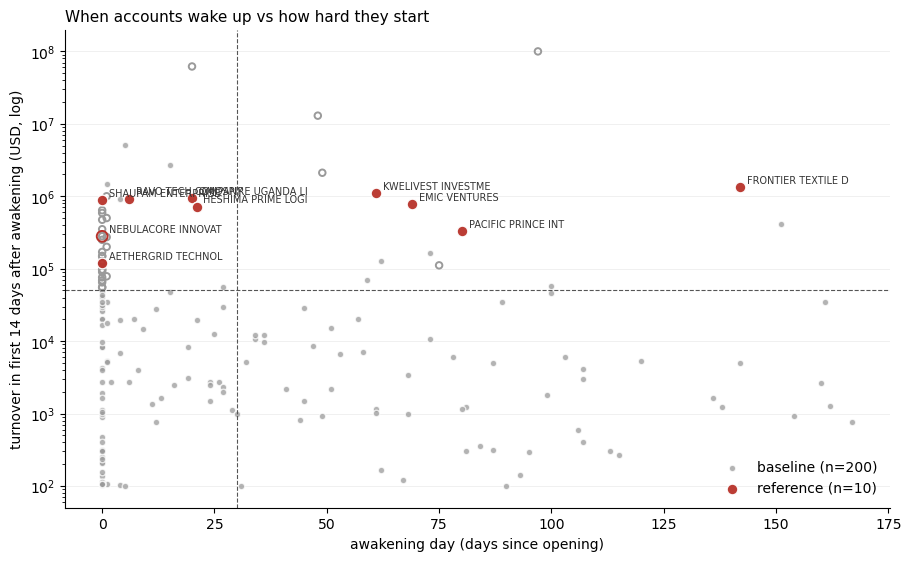

In [11]:
COL = {"cr": "#2a7f9e", "dr": "#c4682b", "chg": "#7a3b8f", "bal": "#3a3a3a", "quiet": "#e6e1d6",
       "ref": "#b8322a", "base": "#9a9a9a"}

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
yfloor = 10
for g, c, sz, lab in [("baseline", COL["base"], 22, f"baseline (n={len(base)})"),
                      ("reference", COL["ref"], 60, f"reference (n={len(ref)})")]:
    s = summary[summary.group == g]
    ok = s.burst_on_wake | (s.wake_turnover < WAKE_MIN_USD)      # hollow only where size passed but shape failed
    kw = dict(s=sz, zorder=3 if g == "reference" else 2)
    ax.scatter(s.awakening_day[ok], s.wake_turnover[ok].clip(lower=yfloor), c=c, alpha=.75 if g == "baseline" else .95,
               edgecolors="white", linewidths=1, label=lab, **kw)
    ax.scatter(s.awakening_day[~ok], s.wake_turnover[~ok].clip(lower=yfloor), facecolors="none", edgecolors=c,
               linewidths=1.4, **kw)
for _, r in ref.iterrows():
    if pd.notna(r.awakening_day):
        ax.annotate(str(r.ACCT_NAME)[:18], (r.awakening_day, max(r.wake_turnover, yfloor)),
                    xytext=(5, 3), textcoords="offset points", fontsize=7, color="#333")
ax.axvline(DORMANT_MIN_DAYS, color="#555", lw=.8, ls="--")
ax.axhline(WAKE_MIN_USD, color="#555", lw=.8, ls="--")
ax.set_yscale("log")
ax.set_xlabel("awakening day (days since opening)")
ax.set_ylabel(f"turnover in first {WAKE_DAYS} days after awakening (USD, log)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eee", lw=.6)
ax.legend(frameon=False, loc="lower right")
ax.set_title("When accounts wake up vs how hard they start", loc="left", fontsize=11)
fig.savefig(OUT / "dormancy_vs_wake_intensity.png", dpi=130)
plt.show()

## 9. Timelines — small multiples (same day-since-opening axis)

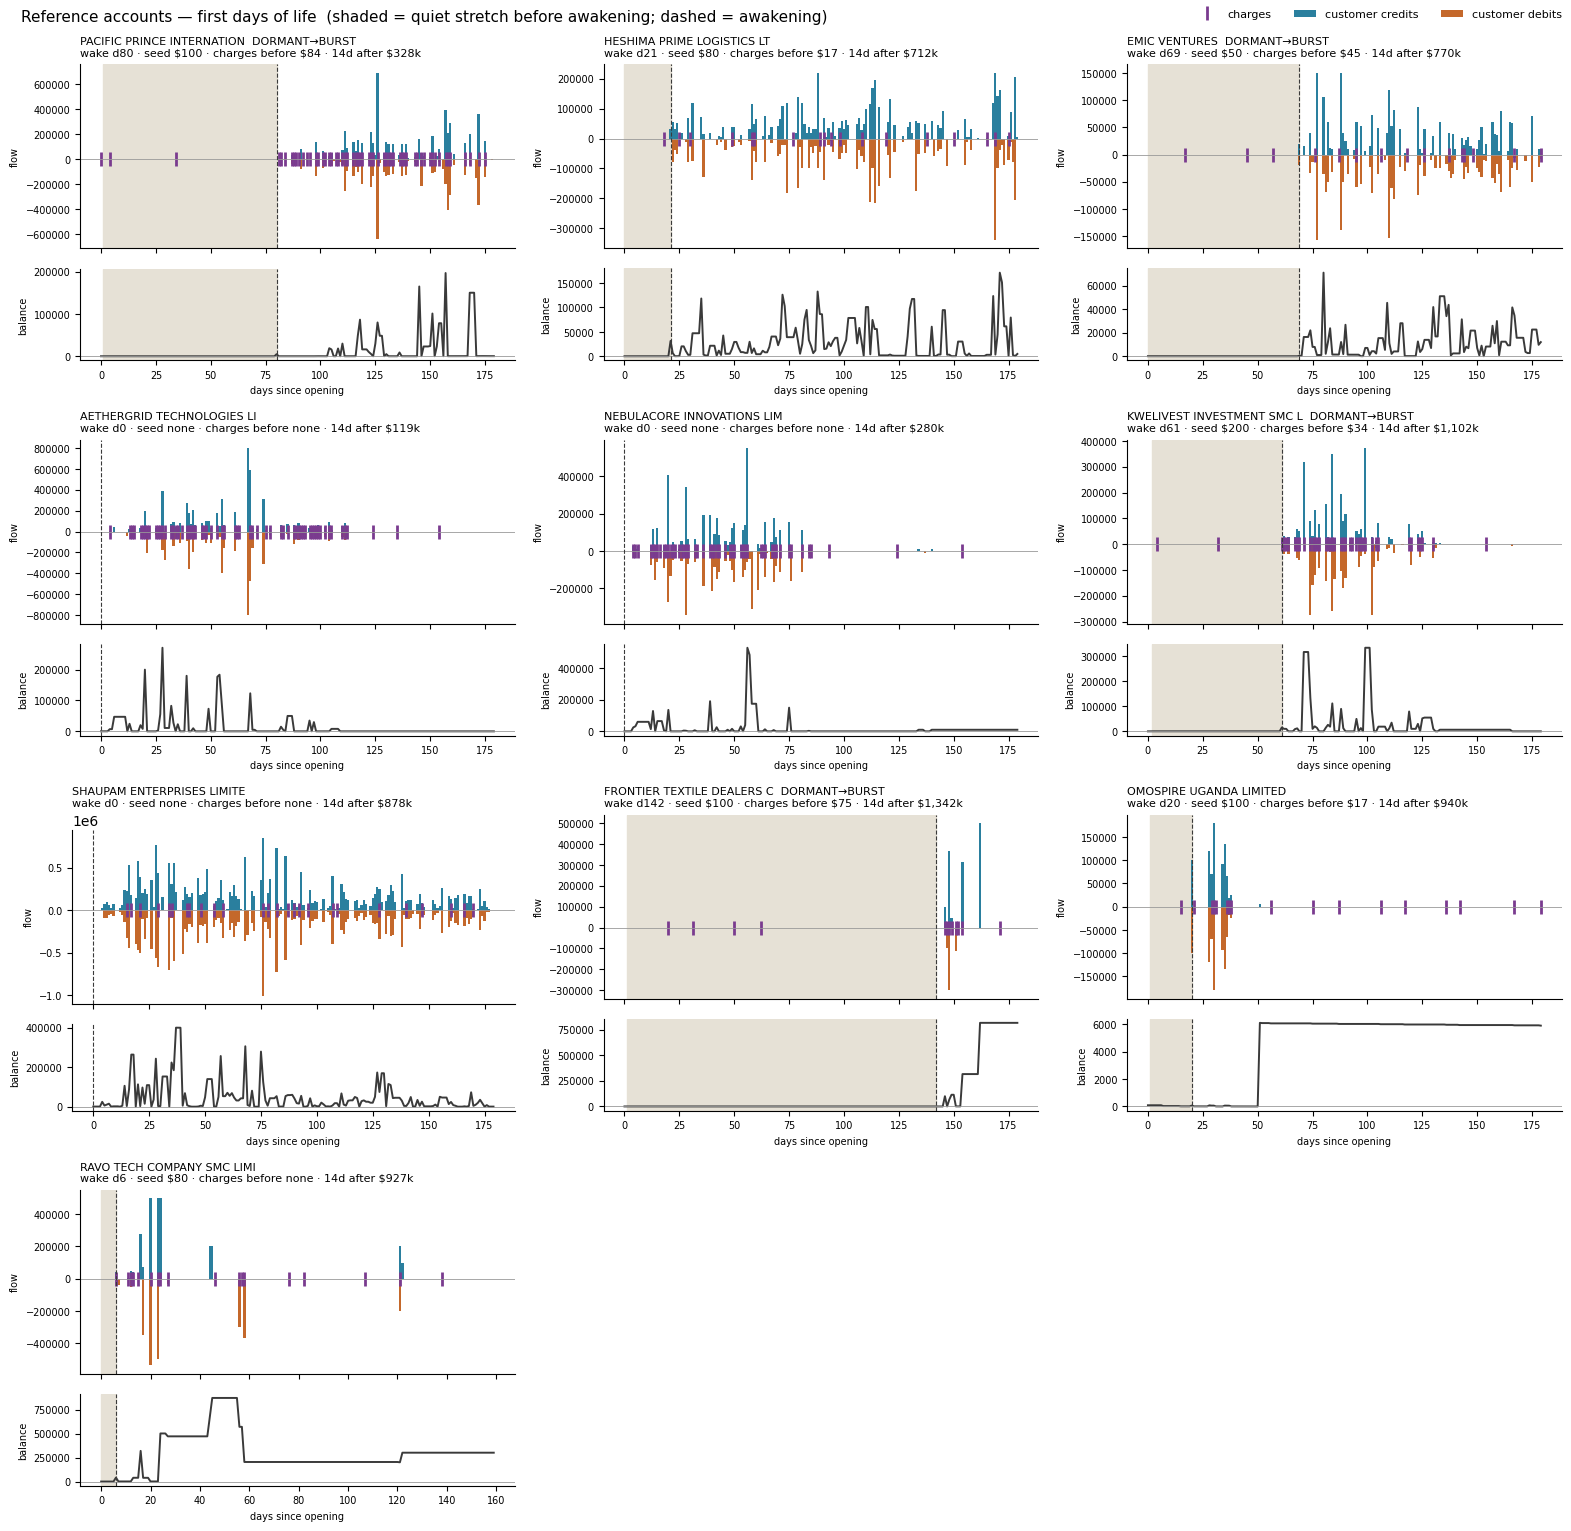

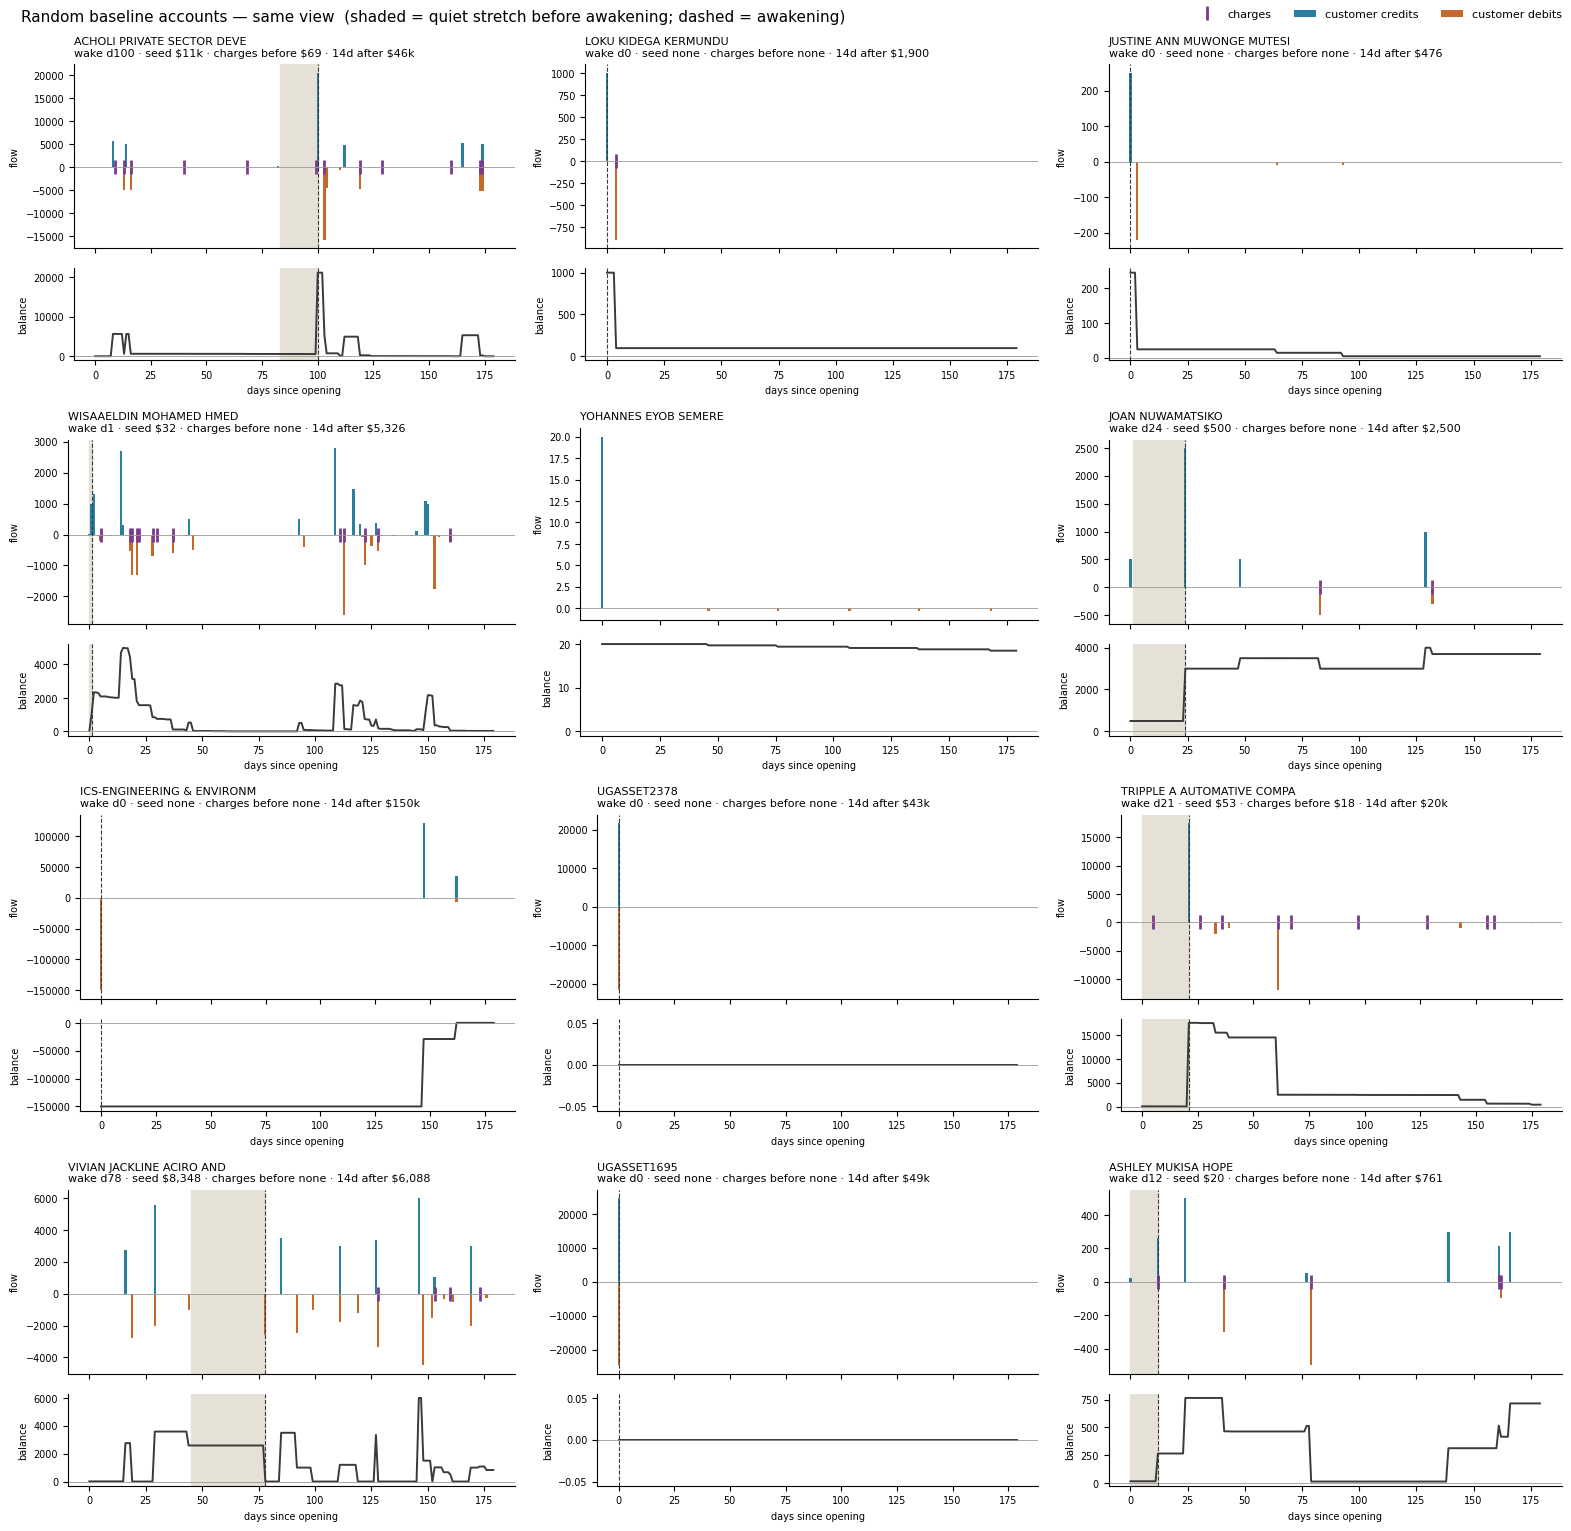

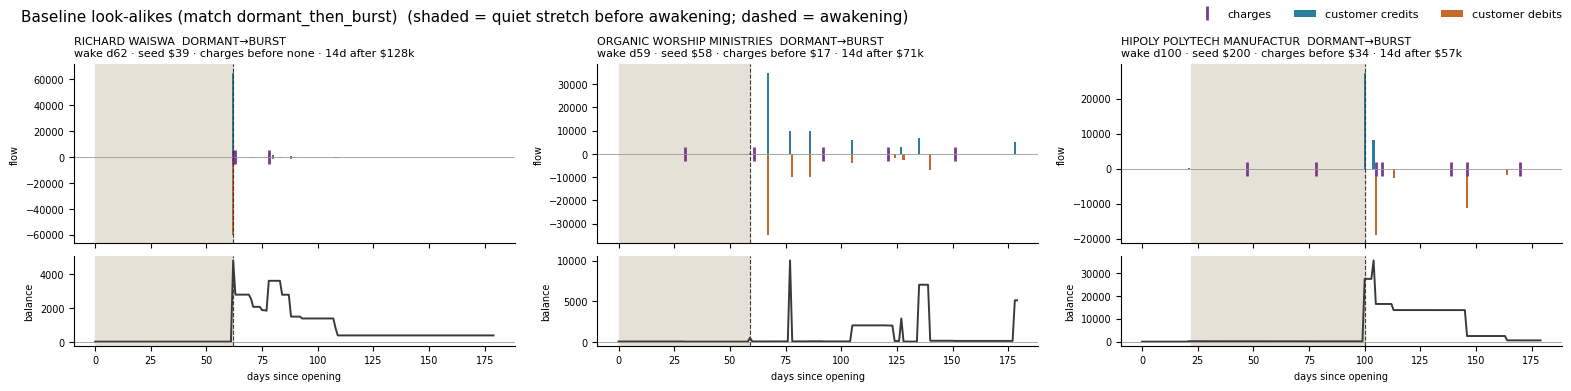

In [12]:
def fmt_usd(v):
    # "\$" stops matplotlib treating text between two dollar signs as math
    return "none" if not v or pd.isna(v) else (f"\\${v/1e3:,.0f}k" if v >= 1e4 else f"\\${v:,.0f}")

def plot_panels(acids, title, fname, ncols=3):
    acids = list(acids)
    if not acids:
        print(f"Nothing to plot for {title}"); return
    nrows = int(np.ceil(len(acids) / ncols))
    fig = plt.figure(figsize=(5.2 * ncols, 3.8 * nrows), constrained_layout=True)
    subs = np.atleast_1d(fig.subfigures(nrows, ncols)).ravel()
    s_idx = summary.set_index("ACID")
    for sf, acid in zip(subs, acids):
        d, s = timelines[acid], s_idx.loc[acid]
        ax, axb = sf.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
        ax.bar(d.index, d.customer_cr, color=COL["cr"], width=1.0, label="customer credits")
        ax.bar(d.index, -d.customer_dr, color=COL["dr"], width=1.0, label="customer debits")
        chg = d.index[d.charge_dr > 0]
        ax.plot(chg, np.zeros(len(chg)), "|", color=COL["chg"], ms=10, mew=2, label="charges")
        ax.axhline(0, color="#999", lw=.6)
        axb.plot(d.index, d.balance, color=COL["bal"], lw=1.4)
        axb.axhline(0, color="#999", lw=.6)
        if pd.notna(s.awakening_day):
            a, qd = int(s.awakening_day), int(s.quiet_before_awake)
            for x in (ax, axb):
                if qd > 0:
                    x.axvspan(a - qd, a, color=COL["quiet"], zorder=0)
                x.axvline(a, color=COL["bal"], lw=.8, ls="--")
        tag = "DORMANT→BURST" if s.dormant_then_burst else ("DORMANT" if s.dormant_start else "")
        info = ""
        if pd.notna(s.awakening_day):
            info = (f"\nwake d{int(s.awakening_day)} · seed {fmt_usd(s.seed_amt)} · "
                    f"charges before {fmt_usd(s.charges_before_wake)} · {WAKE_DAYS}d after {fmt_usd(s.wake_turnover)}")
        ax.set_title(f"{str(s.ACCT_NAME)[:26]}  {tag}{info}", fontsize=8, loc="left")
        ax.tick_params(labelsize=7); axb.tick_params(labelsize=7)
        ax.set_ylabel("flow", fontsize=7); axb.set_ylabel("balance", fontsize=7)
        axb.set_xlabel("days since opening", fontsize=7)
        for x in (ax, axb):
            x.spines[["top", "right"]].set_visible(False)
    for sf in subs[len(acids):]:
        sf.set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper right", ncols=3, fontsize=8, frameon=False)
    fig.suptitle(title + "  (shaded = quiet stretch before awakening; dashed = awakening)", fontsize=11, x=0.01, ha="left")
    fig.savefig(OUT / fname, dpi=130)
    plt.show()

plot_panels(ref.sort_values("ACCT_OPN_DATE").ACID, "Reference accounts — first days of life", "reference_timelines.png")
plot_panels(base.sample(n=min(12, len(base)), random_state=RANDOM_SEED).ACID,
            "Random baseline accounts — same view", "baseline_timelines.png")
plot_panels(lookalikes.ACID.head(12), "Baseline look-alikes (match dormant_then_burst)", "baseline_lookalikes.png")

## 10. Focus account

In [13]:
focus = summary[summary.ACCT_NAME.str.upper().str.contains(FOCUS_NAME, na=False)]
if focus.empty:
    print(f"No account name contains '{FOCUS_NAME}'")
else:
    for acid in focus.ACID:
        d = timelines[acid]
        print(summary.set_index("ACID").loc[acid, ["ACCT_NAME", "FORACID", "group"] + METRICS + FLAGS].to_string())
        active = d[(d.cust_n > 0) | (d.charge_dr > 0) | (d.gl_cr + d.gl_dr > 0)]
        display(active[["customer_cr", "customer_dr", "charge_dr", "gl_cr", "gl_dr", "balance"]].head(40).round(2))

ACCT_NAME                 FRONTIER TEXTILE DEALERS CO LIMITED
FORACID                                         9030027282317
group                                               reference
first_cr_day                                                0
first_dr_day                                              0.0
active_days                                                 9
turnover_first30_share                               0.000062
charge_share_early                                   0.797462
longest_quiet                                           141.0
awakening_day                                           142.0
quiet_before_awake                                      141.0
pre_wake_share                                       0.000068
seed_amt                                                100.0
charges_before_wake                                      75.4
wake_turnover                                      1342094.41
wake_match                                           0.618224
wake_act

,customer_cr,customer_dr,charge_dr,gl_cr,gl_dr,balance
day,,,,,,
0,100.0,11.50,0.00,88.5,88.5,88.50
20,0.0,2.55,17.00,0.0,0.0,68.95
31,0.0,0.00,20.70,0.0,0.0,48.25
50,0.0,2.55,17.00,0.0,0.0,28.70
62,0.0,0.00,20.70,0.0,0.0,8.00
82,0.0,2.55,0.00,0.0,0.0,5.45
94,0.0,2.70,0.00,0.0,0.0,2.75
114,0.0,2.55,0.00,0.0,0.0,0.20
142,103.0,0.00,0.00,0.0,0.0,103.20


## 11. Export

In [15]:
summary.to_csv(OUT / "early_metrics.csv", index=False)
comp.to_csv(OUT / "reference_vs_baseline.csv")
prevalence.to_csv(OUT / "flag_prevalence.csv")
lookalikes.to_csv(OUT / "baseline_lookalikes.csv", index=False)
bursters.to_csv(OUT / "baseline_bursters.csv", index=False)
pd.concat({a: d for a, d in timelines.items() if a in set(ref.ACID)}, names=["ACID"]).to_csv(OUT / "reference_daily_timelines.csv")
print("Saved to", OUT.resolve())

Saved to /home/A270827/experiments/AML/outputs/early_signals


## 12. Gate — what to decide from this

| What you see | Reading | Next step |
|---|---|---|
| `dormant_then_burst` clearly more common in reference than baseline, and better than `burst_on_wake` alone | Dormancy adds real early information | **Lead-time test:** for each reference account, the day it would first reach the current top 5% vs its awakening day |
| `burst_on_wake` separates as well as `dormant_then_burst` | The burst is the signal; dormancy is incidental | Build an awakening detector without the dormancy condition — simpler, covers immediate-start mules too |
| Neither separates (many baseline look-alikes) | Shape alone isn't enough | Combine with onboarding and shared-party signals |

Also check:
- `baseline_bursters`: what are they (narrations)? These set the false-positive rate of an awakening detector.
- `seed_amt` among dormant reference accounts: is there really a lump sum being eaten by charges, or are they empty until they wake?
- The look-alike table: where do those accounts rank in the current production screen?
- `wake_complete = False` rows: young accounts whose look-ahead is cut short, so their `wake_turnover` is understated.

With ~10 reference accounts, treat every number here as directional evidence, not a result.

In [16]:
import os, time
for f in sorted(OUT.glob("*.csv")):
    print(f"{f.name:32s} {time.ctime(os.path.getmtime(f))}")
print("pre_wake_share" in pd.read_csv(OUT / "reference_vs_baseline.csv", index_col=0).index)

baseline_bursters.csv            Sun Oct 18 22:53:52 2026
baseline_lookalikes.csv          Sun Oct 18 22:53:52 2026
early_metrics.csv                Sun Oct 18 22:53:52 2026
flag_prevalence.csv              Sun Oct 18 22:53:52 2026
reference_daily_timelines.csv    Sun Oct 18 22:53:52 2026
reference_vs_baseline.csv        Sun Oct 18 22:53:52 2026
True


In [17]:
# Compact view for sharing: reference accounts + baseline bursters, amounts in $k
pd.set_option("display.width", 250, "display.max_colwidth", 60)
cols = ["ACCT_NAME", "awakening_day", "pre_wake_share", "wake_turnover", "wake_match",
        "wake_active_days", "active_days", "turnover_window"]

def compact(df, extra=()):
    out = df[cols + list(extra)].copy()
    out["ACCT_NAME"] = out.ACCT_NAME.astype(str).str[:22]
    out["wake_$k"] = (out.pop("wake_turnover") / 1e3).round(0)
    out["180d_$k"] = (out.pop("turnover_window") / 1e3).round(0)
    return out.round(2)

def wake_flows(acid, a, n=3):
    '''Biggest customer flows in the first WAKE_DAYS after awakening, by narration.'''
    t = tx[(tx.ACID == acid) & (tx.stream == "customer") & (tx.day >= a) & (tx.day < a + WAKE_DAYS)]
    p = (t.TRAN_PARTICULAR.fillna("").str.upper().str.replace(r"^\d+/", "", regex=True)
           .str.replace(r"\d{4,}", "#", regex=True).str.strip().str[:22])
    g = t.assign(p=p).groupby(["p", "dir"]).TRAN_AMT.sum().sort_values(ascending=False).head(n)
    return " | ".join(f"{d} {k} {v/1e3:,.0f}k" for (k, d), v in g.items())

print("REFERENCE ACCOUNTS")
display(compact(ref, FLAGS[1:2]).sort_values("burst_on_wake"))

print(f"\nBASELINE BURSTERS ({len(bursters)})")
b = compact(bursters)
b["top_wake_flows"] = [wake_flows(a, int(d)) for a, d in zip(bursters.ACID, bursters.awakening_day)]
display(b.sort_values("wake_$k", ascending=False))

print("\nWhole-window activity, medians:")
print(pd.DataFrame({"mules": ref[["active_days", "turnover_window"]].median(),
                    "bursters": bursters[["active_days", "turnover_window"]].median(),
                    "baseline": base[["active_days", "turnover_window"]].median()}).round(0))

REFERENCE ACCOUNTS


,ACCT_NAME,awakening_day,pre_wake_share,wake_match,wake_active_days,active_days,burst_on_wake,wake_$k,180d_$k
140,NEBULACORE INNOVATIONS,0.0,0.0,0.37,6.0,54,False,280.0,8751.0
29,OMOSPIRE UGANDA LIMITE,20.0,0.0,1.00,4.0,11,True,940.0,1616.0
38,HESHIMA PRIME LOGISTIC,21.0,0.0,0.88,8.0,104,True,712.0,10378.0
39,PACIFIC PRINCE INTERNA,80.0,0.0,1.00,9.0,64,True,328.0,11321.0
44,AETHERGRID TECHNOLOGIE,0.0,0.0,0.66,5.0,67,True,119.0,11994.0
94,RAVO TECH COMPANY SMC,6.0,0.0,0.92,7.0,17,True,927.0,5064.0
136,EMIC VENTURES,69.0,0.0,0.97,8.0,67,True,770.0,4491.0
149,FRONTIER TEXTILE DEALE,142.0,0.0,0.62,7.0,9,True,1342.0,1842.0
194,KWELIVEST INVESTMENT S,61.0,0.0,0.78,8.0,46,True,1102.0,5618.0
199,SHAUPAM ENTERPRISES LI,0.0,0.0,0.99,9.0,140,True,878.0,47960.0



BASELINE BURSTERS (10)


,ACCT_NAME,awakening_day,pre_wake_share,wake_match,wake_active_days,active_days,wake_$k,180d_$k,top_wake_flows
204,LAROIT - SMC LTD,5.0,0.00,1.00,13.0,20,5044.0,10015.0,dr PROGOV 480k | dr HAJIYALE 381k | dr DADA 367k
0,FLAVIO PASQUALATO,15.0,0.00,0.64,4.0,11,2681.0,3193.0,"cr COMPANY DIVIDEND 1,632k | dr FLAVIO PASQUALATO 550k |..."
168,DREXON TRADERS,1.0,0.00,1.00,8.0,21,1479.0,2595.0,dr I 721k | cr SCOTT WEINSTOCK 143k | cr SHAHROKH SHEYBA...
109,JESA FARM DAIRY LIMITE,4.0,0.00,0.64,6.0,28,925.0,1958.0,cr PURCHASE OF USD 460k | dr PAYMNT OF NUMEROUS INV 156k...
124,KAMP GROUP LIMITED,151.0,0.36,0.65,4.0,18,411.0,706.0,cr GORM PEDERSEN HOLDING 250k | dr DEBIT NOTES 91k | dr...
152,STAMP ENGINEERING UG L,73.0,0.19,1.00,3.0,18,163.0,519.0,cr # DISBURSEMENT CREDIT 82k | dr # - PAYOFF SOURCE A/C ...
75,RICHARD WAISWA,62.0,0.00,0.97,5.0,12,128.0,138.0,cr RICHARD WAISWA 65k | dr CLIPPER LOGISTICS EURO 60k | ...
150,ORGANIC WORSHIP MINIST,59.0,0.00,1.00,3.0,13,71.0,147.0,cr LIFE BIBLE CHURCH 35k | dr KINTU JULIUS 35k | dr IAT ...
91,HIPOLY POLYTECH MANUFA,100.0,0.00,0.61,4.0,7,57.0,71.0,cr DONG FEL 27k | dr PET FLAKES NO RF HF # 19k | cr DONG...
110,LOTUS MARINE LOGISTICS,27.0,0.21,1.00,3.0,11,56.0,211.0,dr KATENDE RICHARD MUKIIB 28k | cr INVOICE 62 15k | cr K...



Whole-window activity, medians:
                     mules  bursters  baseline
active_days           59.0      16.0       4.0
turnover_window  7184786.0  612334.0   10604.0
